In [1]:
import os, sys, glob
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

WORK = "/kaggle/working"
DATA_DIR = f"{WORK}/data"
OUT_DIR = f"{WORK}/outputs"
RESULTS_DIR = f"{WORK}/results"
for d in (DATA_DIR, OUT_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

def find(name):
    hits = sorted(glob.glob(f"{WORK}/**/{name}", recursive=True)) + \
           sorted(glob.glob(f"/kaggle/input/**/{name}", recursive=True))
    if not hits:
        raise FileNotFoundError(f"{name} not found: attach the dataset/notebook that makes it (Add Input)")
    if len(hits) > 1:
        print(f"note: {len(hits)} copies of {name}, using {hits[0]}")
    return hits[0]

RAW_CSV = find("afri_med_qa_15k_v2.4_phase_2_15275.csv")

HF_USER = "Tresor26"
def hub_id(run_name):
    return f"{HF_USER}/clinicmate-{run_name}"

from kaggle_secrets import UserSecretsClient
from huggingface_hub import login
login(token=UserSecretsClient().get_secret("HF_TOKEN"))

REPO = "/kaggle/temp/ClinicMate"
if not os.path.exists(REPO):
    !git clone -q https://github.com/Tresorshingiro/ClinicMate.git {REPO}
else:
    !git -C {REPO} pull -q
sys.path.append(REPO)

import random, numpy as np
SEED = 42
random.seed(SEED); np.random.seed(SEED)

In [2]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 200)

BEST = "E2_qwen1.5b_r16"
BASE = "B3_zeroshot_1.5b"

def pred_path(name):
    hits = sorted(glob.glob(f"/kaggle/input/**/preds_{name}.jsonl", recursive=True))
    path = hits[0] if hits else f"{REPO}/results/preds_{name}.jsonl"
    print("using", path)
    return path

## Load predictions

In [3]:
def load_preds(name):
    p = pd.read_json(pred_path(name), lines=True)
    p["gold"] = p["answer_letters"].map(lambda a: a[0] if isinstance(a, list) and a else None)
    return p

p, base = load_preds(BEST), load_preds(BASE)
mcq = p[p.qtype == "mcq"].copy()
mcq["correct"] = mcq["correct"].astype(bool)
base_mcq = base[base.qtype == "mcq"].copy()
base_mcq["correct"] = base_mcq["correct"].astype(bool)
saq = p[p.qtype == "saq"].copy()

# sanity check: these must match eval_*.json from notebook 06
for name, m in [(BEST, mcq), (BASE, base_mcq)]:
    print(f"{name}: MCQ acc {m['correct'].mean():.3f} on {len(m)} questions")
print(len(p), "predictions,", len(mcq), "MCQ,", len(saq), "SAQ")

using /kaggle/input/notebooks/tresorshingiro/06-evaluation-ipynb/results/preds_E2_qwen1.5b_r16.jsonl
using /kaggle/input/notebooks/tresorshingiro/06-evaluation-ipynb/results/preds_B3_zeroshot_1.5b.jsonl
E2_qwen1.5b_r16: MCQ acc 0.541 on 739 questions
B3_zeroshot_1.5b: MCQ acc 0.498 on 739 questions
982 predictions, 739 MCQ, 243 SAQ


## 1 · MCQ accuracy by specialty

Only specialties with ≥10 test questions. Smaller groups are mostly noise.

                            mean  count  base_mean   gain
specialty                                                
Hematology                 0.333     15      0.467 -0.133
Cardiology                 0.436     39      0.385  0.051
Pulmonary_Medicine         0.450     20      0.300  0.150
Orthopedic_Surgery         0.455     11      0.364  0.091
Obstetrics_and_Gynecology  0.466    116      0.379  0.086
Internal_Medicine          0.500     14      0.500  0.000
Infectious_Disease         0.512     41      0.537 -0.024
Ophthalmology              0.533     15      0.400  0.133
Pathology                  0.537     54      0.574 -0.037
Pediatrics                 0.543     94      0.436  0.106
Neurology                  0.545     33      0.606 -0.061
Gastroenterology           0.559     34      0.471  0.088
Nephrology                 0.583     12      0.667 -0.083
General_Surgery            0.589     95      0.589  0.000
Endocrinology              0.594     32      0.562  0.031
Psychiatry    

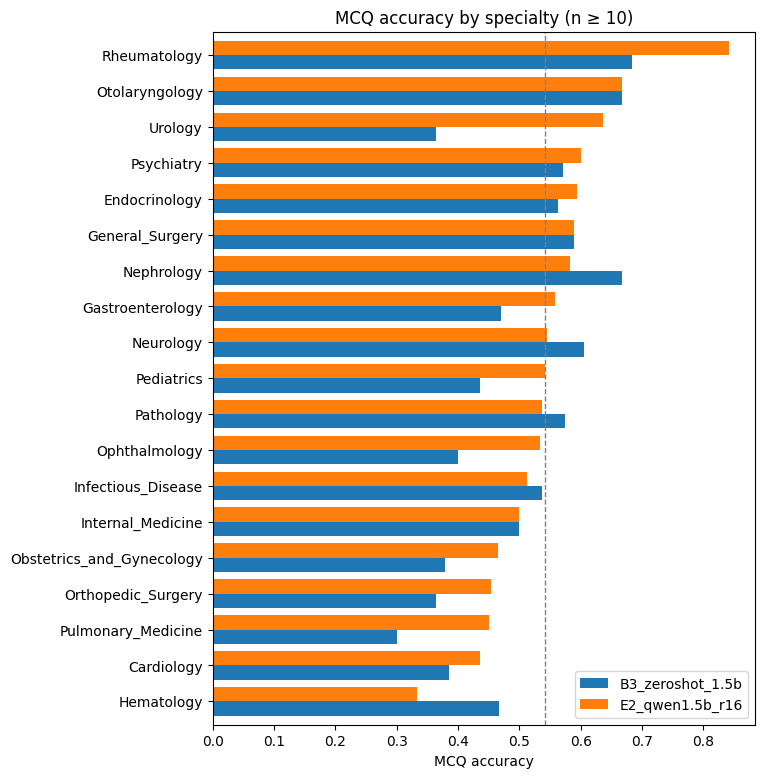

In [4]:
by_spec = (mcq.groupby("specialty")["correct"].agg(["mean", "count"])
           .join(base_mcq.groupby("specialty")["correct"].mean().rename("base_mean"))
           .query("count >= 10").sort_values("mean"))
by_spec["gain"] = by_spec["mean"] - by_spec["base_mean"]
print(by_spec.round(3))

ax = by_spec[["base_mean", "mean"]].rename(columns={"base_mean": BASE, "mean": BEST}) \
        .plot.barh(figsize=(7, 9), width=0.8)
ax.axvline(mcq["correct"].mean(), ls="--", c="grey", lw=1)
ax.set_xlabel("MCQ accuracy"); ax.set_ylabel("")
ax.set_title("MCQ accuracy by specialty (n ≥ 10)")
plt.savefig(f"{RESULTS_DIR}/err_acc_by_specialty.png", dpi=150, bbox_inches="tight"); plt.show()

## 2 · Tier and question-writer country

The crowdsourced MCQ group is tiny (about 25 questions), so treat its accuracy as indicative only.

In [5]:
def acc_table(col):
    t = mcq.groupby(col)["correct"].agg(["mean", "count"]) \
           .join(base_mcq.groupby(col)["correct"].mean().rename("base_mean"))
    return t.query("count >= 10").sort_values("count", ascending=False).round(3)

print(acc_table("tier"), "\n")
print(acc_table("country"))

               mean  count  base_mean
tier                                 
expert        0.536    714      0.489
crowdsourced  0.680     25      0.760 

          mean  count  base_mean
country                         
GH       0.502    281      0.498
NG       0.547    274      0.500
KE       0.575    106      0.538
MW       0.612     67      0.433
ZA       0.636     11      0.455


## 3 · Question length and number of options

Long questions are usually clinical vignettes that need several reasoning steps.
`pd.qcut` makes four equal-sized groups by word count.

In [6]:
mcq["n_words"] = mcq["question"].str.split().str.len()
mcq["len_bucket"] = pd.qcut(mcq["n_words"], 4)
mcq["n_options"] = mcq["options"].str.len()
print(mcq.groupby("len_bucket", observed=True)["correct"].agg(["mean", "count"]).round(3), "\n")
print(mcq.groupby("n_options")["correct"].agg(["mean", "count"]).round(3))

                mean  count
len_bucket                 
(1.999, 9.0]   0.517    207
(9.0, 12.0]    0.500    164
(12.0, 24.5]   0.568    183
(24.5, 119.0]  0.578    185 

            mean  count
n_options              
2          1.000      4
4          0.584    178
5          0.524    557


## 4 · Position bias: gold letter vs predicted letter

Rows are the correct letter, columns the predicted letter. If a column total is much bigger than
the matching row total, the model favours that letter regardless of content.
E is genuinely rarer because many questions only have 4 options.

== B3_zeroshot_1.5b
pred    A    B    C    D   E  All
gold                             
A      85   21   22   13  13  154
B      33   81   20   13  10  157
C      37   20   86   19   7  169
D      32   19   34   87  10  182
E      16   13   11    8  29   77
All   203  154  173  140  69  739 

== E2_qwen1.5b_r16
pred    A    B    C    D   E  All
gold                             
A      68   31   17   25  13  154
B      20   91   19   17  10  157
C      20   18   94   28   9  169
D      19   17   17  114  15  182
E      10   16    9    9  33   77
All   137  173  156  193  80  739 

    gold  B3_zeroshot_1.5b  E2_qwen1.5b_r16
A  0.208             0.275            0.185
B  0.212             0.208            0.234
C  0.229             0.234            0.211
D  0.246             0.189            0.261
E  0.104             0.093            0.108


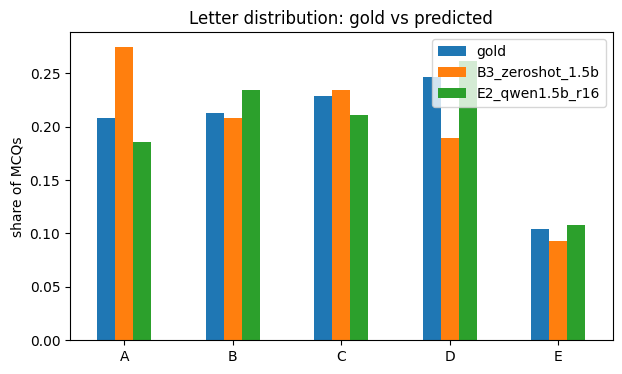

In [7]:
for name, m in [(BASE, base_mcq), (BEST, mcq)]:
    print(f"== {name}")
    print(pd.crosstab(m["gold"], m["pred"], margins=True), "\n")

dist = pd.DataFrame({
    "gold": mcq["gold"].value_counts(normalize=True),
    BASE: base_mcq["pred"].value_counts(normalize=True),
    BEST: mcq["pred"].value_counts(normalize=True),
}).reindex(list("ABCDE")).fillna(0)
print(dist.round(3))
dist.plot.bar(figsize=(7, 4), rot=0)
plt.ylabel("share of MCQs"); plt.title("Letter distribution: gold vs predicted")
plt.savefig(f"{RESULTS_DIR}/err_letter_distribution.png", dpi=150, bbox_inches="tight"); plt.show()

## 5 · What did fine-tuning fix or break?

*Fixed* = wrong before fine-tuning, right after. *Broken* = the reverse.
These are the off-diagonal counts of the McNemar test in notebook 06.

In [8]:
mm = mcq.merge(base_mcq[["id", "correct", "pred"]], on="id", suffixes=("", "_base"))
fixed = mm[mm.correct & ~mm.correct_base]
broken = mm[~mm.correct & mm.correct_base]
print(len(fixed), "fixed;", len(broken), "broken; net gain", len(fixed) - len(broken))

def show(df, n=5):
    for _, r in df.head(n).iterrows():
        opts = "\n".join(f"   {'ABCDE'[i]}. {o}" for i, o in enumerate(r["options"]))
        print(f"[{r['specialty']}] {r['question']}\n{opts}\n   gold={r['gold']}  "
              f"base={r['pred_base']}  fine-tuned={r['pred']}\n")

print("===== BROKEN by fine-tuning =====\n"); show(broken.sample(min(5, len(broken)), random_state=7))
print("===== FIXED by fine-tuning =====\n");  show(fixed.sample(min(5, len(fixed)), random_state=7))

98 fixed; 66 broken; net gain 32
===== BROKEN by fine-tuning =====

[Gastroenterology] Hepatic tuberculosis may manifest as all of the following except?
   A. Miliary tuberculosis
   B. Tuberculous hepatitis
   C. Tuberculomas
   D. Tuberculous abscess
   E. Rich focus
   gold=E  base=E  fine-tuned=A

[Gastroenterology] A 69 yr old man with history of Chronic alcohol intake presented with with yellowness of the eyes, weight loss of 5 months duration. Examination findings revealed stigmata of CLD, with hard liver with scaloped edges.
Which biomarker will help to clinch the diagnosis?
   A. CA-125
   B. CEA
   C. C.19-19
   D. AFP
   gold=D  base=D  fine-tuned=C

[Cardiology] Cardiac causes of finger clubbing include
   A. Transposition of the great vessels
   B. Atrial septal defect
   C. Patent ductus arteriosus
   D. Hypertrophic cardiomyopathy
   E. Ventricular septal defect
   gold=A  base=A  fine-tuned=D

[Pathology] Fungi differ from bacteria in that they
   A. do not conatin pept

## 6 · SAQ: what the metrics say

ROUGE-L and BERTScore reward answers whose length and wording match the reference,
so check how answer length relates to the scores before reading too much into them.
Crowdsourced SAQs have no specialty, so they all appear as `unknown` in the specialty table.

              rougeL  bertscore  pred_words  ref_words
tier                                                  
crowdsourced   0.345      0.417      35.674     36.229
expert         0.155      0.008      57.706     63.544 

                  rougeL       bertscore      
                    mean count      mean count
specialty                                     
General_Surgery    0.132    30    -0.031    30
Pediatrics         0.149    11     0.026    11
Internal_Medicine  0.192    12     0.041    12
unknown            0.345   175     0.417   175 

length vs BERTScore, Spearman: -0.255
|pred - ref| length vs BERTScore, Spearman: -0.418
B3_zeroshot_1.5b: avg 137 words, ~38.7% look truncated
E2_qwen1.5b_r16: avg 42 words, ~0.8% look truncated


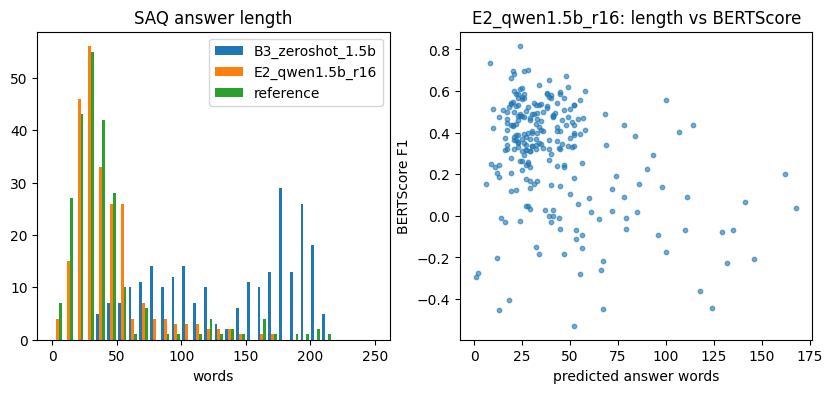

In [9]:
saq["pred_words"] = saq["pred"].str.split().str.len()
saq["ref_words"] = saq["rationale"].str.split().str.len()
base_saq = base[base.qtype == "saq"].copy()
base_saq["pred_words"] = base_saq["pred"].str.split().str.len()

print(saq.groupby("tier")[["rougeL", "bertscore", "pred_words", "ref_words"]].mean().round(3), "\n")
spec = saq.groupby("specialty")[["rougeL", "bertscore"]].agg(["mean", "count"])
print(spec[spec[("bertscore", "count")] >= 8].sort_values(("bertscore", "mean")).round(3), "\n")

print("length vs BERTScore, Spearman:",
      round(saq[["pred_words", "bertscore"]].corr(method="spearman").iloc[0, 1], 3))
print("|pred - ref| length vs BERTScore, Spearman:",
      round(pd.Series((saq.pred_words - saq.ref_words).abs()).corr(saq.bertscore, method="spearman"), 3))

# answers that probably hit the 256-token limit: long and not ending in punctuation
for name, d in [(BASE, base_saq), (BEST, saq)]:
    cut = (d["pred_words"] > 150) & ~d["pred"].str.rstrip().str[-1:].isin(list(".!?)*"))
    print(f"{name}: avg {d['pred_words'].mean():.0f} words, ~{cut.mean():.1%} look truncated")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].hist([base_saq["pred_words"], saq["pred_words"], saq["ref_words"]], bins=30,
           label=[BASE, BEST, "reference"], range=(0, 250))
ax[0].set_xlabel("words"); ax[0].legend(); ax[0].set_title("SAQ answer length")
ax[1].scatter(saq["pred_words"], saq["bertscore"], s=10, alpha=0.6)
ax[1].set_xlabel("predicted answer words"); ax[1].set_ylabel("BERTScore F1")
ax[1].set_title(f"{BEST}: length vs BERTScore")
plt.savefig(f"{RESULTS_DIR}/err_saq_length.png", dpi=150, bbox_inches="tight"); plt.show()

## 7 · SAQ error sheet (label by hand)

The 25 lowest- and 10 highest-BERTScore answers go into `saq_error_sheet.csv`.
Download it from the notebook's **Output** tab, open it in Google Sheets or Excel and fill `error_type` for the 25 **worst** rows with one number:

1. Factual error / hallucination (wrong drug, dose, fact)
2. Omission: correct but incomplete
3. Non-African context: ignores local availability or guidelines
4. Verbosity or truncation
5. Metric artefact: correct but worded differently
6. Poor or ambiguous gold answer

The 10 best rows give you good examples for the report and video.

In [10]:
op = saq.sort_values("bertscore")
sheet = pd.concat([op.head(25).assign(bucket="worst"), op.tail(10).assign(bucket="best")])[
    ["id", "bucket", "specialty", "tier", "question", "rationale", "pred", "rougeL", "bertscore"]
].assign(error_type="")
sheet.to_csv(f"{RESULTS_DIR}/saq_error_sheet.csv", index=False)
print(sheet[["bucket", "specialty", "bertscore"]].groupby("bucket").describe().round(3))

       bertscore                                                 
           count   mean    std    min    25%    50%    75%    max
bucket                                                           
best        10.0  0.695  0.052  0.629  0.666  0.690  0.702  0.818
worst       25.0 -0.239  0.135 -0.528 -0.296 -0.208 -0.149 -0.070


## 8 · Count the error categories (run after labelling)

Save the labelled sheet as **`saq_error_sheet_labelled.csv`**, upload it as a Kaggle dataset
(Add Input → Upload), then re-run this cell. Until then it just prints a reminder.

In [11]:
hits = glob.glob("/kaggle/input/**/saq_error_sheet_labelled.csv", recursive=True)
LABELLED = hits[0] if hits else ""
CATS = {1: "Factual error / hallucination", 2: "Omission", 3: "Non-African context",
        4: "Verbosity / truncation", 5: "Metric artefact", 6: "Poor gold answer"}
if LABELLED:
    lab = pd.read_csv(LABELLED)
    worst = lab[lab.bucket == "worst"].dropna(subset=["error_type"])
    counts = worst["error_type"].astype(int).map(CATS).value_counts()
    print(f"{len(worst)} of 25 labelled\n"); print(counts)
    counts.sort_values().plot.barh(figsize=(6, 3)); plt.xlabel("answers")
    plt.title("Error categories, 25 worst SAQ answers")
    plt.savefig(f"{RESULTS_DIR}/err_saq_categories.png", dpi=150, bbox_inches="tight"); plt.show()
    counts.to_csv(f"{RESULTS_DIR}/saq_error_counts.csv")
else:
    print("No saq_error_sheet_labelled.csv attached yet: label the sheet, upload it, re-run.")

No saq_error_sheet_labelled.csv attached yet: label the sheet, upload it, re-run.


## Outputs

Save Version → Output tab → download `results/` and copy the new files into the repo's `results/` folder.

In [12]:
print(sorted(f for f in os.listdir(RESULTS_DIR) if f.startswith(("err_", "saq_error"))))

['err_acc_by_specialty.png', 'err_letter_distribution.png', 'err_saq_length.png', 'saq_error_sheet.csv']
